# US banking stress in March 2023

Daily industry returns, statistical detection and industry networks. See README.md for the research question, final findings, setup and limitations. The complete report is in reports/banking_stress_2023_report.pdf.

Run from the project root, with the two source CSVs in data/raw. Restart the kernel and run all cells in order. Source vintage: 202608.

Exploratory examples and learning notes are retained. The final historical configuration is a threshold of 3.22, CUSUM k=0.5 and h=5.45, with a reset after each alarm. Earlier illustrative settings are not the final configuration.

The study is retrospective and descriptive. Correlation networks do not establish causal transmission, and the alarms do not demonstrate crisis prediction.


In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Project environment ready")




Project environment ready


In [3]:
print("Kernel is responding")

Kernel is responding


In [4]:
from pathlib import Path

data_folder = Path("data/raw")
print([file.name for file in data_folder.iterdir()])

['F-F_Research_Data_Factors_daily.csv', '49_Industry_Portfolios_Daily.csv']


In [ ]:
from pathlib import Path
import sys

print("Working folder:", Path.cwd())
print("Python executable:", sys.executable)

data_folder = Path("data/raw")
print("Data folder:", data_folder.resolve())
print("Files:", [file.name for file in data_folder.iterdir()])

In [6]:
file_path = data_folder / "49_Industry_Portfolios_Daily.csv"

with file_path.open("r") as file:
    for line_number in range(15):
        line = file.readline()
        print(line_number, line.rstrip())

0 This file was created using the 202608 CRSP database.
1 It contains value- and equal-weighted returns for 49 industry portfolios.
2 
3 The portfolios are constructed at the end of June.
4 
5 Missing data are indicated by -99.99 or -999.
6 
7 
8   Average Value Weighted Returns -- Daily
9 ,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,Clths,Hlth,MedEq,Drugs,Chems,Rubbr,Txtls,BldMt,Cnstr,Steel,FabPr,Mach,ElcEq,Autos,Aero,Ships,Guns,Gold,Mines,Coal,Oil,Util,Telcm,PerSv,BusSv,Hardw,Softw,Chips,LabEq,Paper,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
10 19260701,   0.56,  -0.07, -99.99,  -1.39,   0.00,  -1.44,   0.62,  -1.27,  -0.90,   0.12, -99.99,   2.69,   0.50,   0.57, -99.99,   0.18,   0.27,  -0.48,  -0.62, -99.99,   0.05,  -0.21,  -0.14,   0.00,  -0.45, -99.99, -99.99,   0.46,   0.12,   0.61,   0.61,  -0.02, -99.99,   1.46,  -0.34, -99.99,  -0.98,   0.00, -99.99,  -0.93,   0.14,   2.77,  -0.02,   0.27,   0.59,   0.47,   0.81,   0.57,  -1.66
11 19260702,   0.29,   0.06

In [7]:
with file_path.open("r") as file:
    lines = file.readlines()

for line_number, line in enumerate(lines):
    if "Average" in line:
        print(line_number, line.strip())

8 Average Value Weighted Returns -- Daily
26329 Average Equal Weighted Returns -- Daily


In [8]:
from io import StringIO

start = next(
    i for i, line in enumerate(lines)
    if "Average Value Weighted Returns -- Daily" in line
)

end = next(
    i for i, line in enumerate(lines)
    if "Average Equal Weighted Returns -- Daily" in line
)

table_text = "".join(lines[start + 1:end])

industry_returns = pd.read_csv(
    StringIO(table_text),
    index_col=0,
    skipinitialspace=True,
    na_values=[-99.99, -999]
)

print(industry_returns.shape)
industry_returns.head()

(26317, 49)


,Agric,Food,Soda,Beer,Smoke,Toys,Fun,Books,Hshld,Clths,Hlth,MedEq,Drugs,Chems,Rubbr,Txtls,BldMt,Cnstr,Steel,FabPr,Mach,ElcEq,Autos,Aero,Ships,Guns,Gold,Mines,Coal,Oil,Util,Telcm,PerSv,BusSv,Hardw,Softw,Chips,LabEq,Paper,Boxes,Trans,Whlsl,Rtail,Meals,Banks,Insur,RlEst,Fin,Other
19260701,0.56,-0.07,NaN,-1.39,0.00,-1.44,0.62,-1.27,-0.90,0.12,NaN,2.69,0.50,0.57,NaN,0.18,0.27,-0.48,-0.62,NaN,0.05,-0.21,-0.14,0.00,-0.45,NaN,NaN,0.46,0.12,0.61,0.61,-0.02,NaN,1.46,-0.34,NaN,-0.98,0.00,NaN,-0.93,0.14,2.77,-0.02,0.27,0.59,0.47,0.81,0.57,-1.66
19260702,0.29,0.06,NaN,0.78,0.70,1.46,0.03,0.00,-0.34,-0.35,NaN,1.35,-0.21,0.98,NaN,0.36,-0.19,-0.97,1.18,NaN,0.42,0.18,1.05,-1.96,-0.11,NaN,NaN,0.77,-0.13,0.71,0.47,0.26,NaN,0.71,-0.59,NaN,0.58,1.80,NaN,1.07,0.07,0.00,0.01,-0.10,1.04,-0.03,-0.61,-1.03,3.09
19260706,-0.33,0.18,NaN,-1.74,0.50,-0.96,-0.06,4.27,-1.20,0.41,NaN,0.71,0.10,0.19,NaN,0.26,0.49,0.74,0.17,NaN,0.62,0.44,0.69,1.33,0.13,NaN,NaN,-0.33,-0.02,0.18,0.73,0.17,NaN,-0.05,0.49,NaN,0.29,0.66,NaN,0.73,-0.20,0.77,-0.22,-0.67,0.45,0.31,-0.72,0.62,1.41
19260707,3.57,-0.15,NaN,-1.73,-0.12,-0.49,-0.06,-4.10,-0.22,0.16,NaN,0.96,0.15,0.80,NaN,0.24,-0.10,-0.61,-0.03,NaN,-0.10,0.03,0.18,-1.32,-0.46,NaN,NaN,-0.11,-0.25,-0.02,0.17,0.32,NaN,1.38,-0.37,NaN,-0.24,-0.66,NaN,2.22,0.18,-3.21,-0.57,-1.08,-1.09,0.21,0.07,0.17,0.62
19260708,0.30,1.12,NaN,-0.15,0.30,-0.49,0.24,0.00,-0.01,0.79,NaN,0.00,1.18,-0.13,NaN,0.64,0.29,0.86,-0.07,NaN,0.64,0.30,0.23,2.67,0.45,NaN,NaN,0.23,0.48,0.09,-0.20,0.40,NaN,-0.36,0.61,NaN,1.15,0.33,NaN,-0.39,0.46,-1.10,-0.38,0.33,0.99,-0.88,-0.36,-1.10,0.98


In [9]:
returns = industry_returns.copy()

returns.index = pd.to_datetime(
    returns.index.astype(str),
    format="%Y%m%d"
)
returns.index.name = "Date"

returns = returns / 100

returns = returns.loc["2022-01-01":"2023-04-28"]

print(returns.shape)
returns[["Banks", "Insur", "RlEst"]].head()

(332, 49)


,Banks,Insur,RlEst
Date,,,
2022-01-03,0.0251,-0.0006,0.0029
2022-01-04,0.0248,-0.0019,0.0091
2022-01-05,-0.0123,-0.0067,-0.0372
2022-01-06,0.0176,-0.0178,-0.0084
2022-01-07,0.0091,-0.0008,-0.0096


In [10]:
print("Date range:", returns.index.min(), "to", returns.index.max())
print("Dates in chronological order:", returns.index.is_monotonic_increasing)
print("Duplicate dates:", returns.index.duplicated().sum())

missing = returns.isna().sum()
print("Columns with missing values:")
print(missing[missing > 0])

Date range: 2022-01-03 00:00:00 to 2023-04-28 00:00:00
Dates in chronological order: True
Duplicate dates: 0
Columns with missing values:
Series([], dtype: int64)


In [11]:
factor_path = data_folder / "F-F_Research_Data_Factors_daily.csv"

with factor_path.open("r") as file:
    for line_number in range(15):
        print(line_number, file.readline().rstrip())

0 This file was created by using the 202608 CRSP database.
1 The Tbill return is the simple daily rate that, over the number of trading days
2 compounds to 1-month TBill rate. The 1-month TBill rate data until 202405 are from Ibbotson Associates. Starting from 202406, the 1-month TBill rate is from ICE BofA US 1-Month Treasury Bill Index.
3 
4 ,Mkt-RF,SMB,HML,RF
5 19260701,    0.09,   -0.23,   -0.28,    0.01
6 19260702,    0.45,   -0.34,   -0.03,    0.01
7 19260706,    0.17,    0.29,   -0.38,    0.01
8 19260707,    0.09,   -0.62,    0.03,    0.01
9 19260708,    0.22,   -0.38,    0.18,    0.01
10 19260709,   -0.71,    0.44,    0.58,    0.01
11 19260710,    0.61,   -0.52,   -0.13,    0.01
12 19260712,    0.04,    0.03,    0.57,    0.01
13 19260713,    0.48,   -0.25,   -0.25,    0.01
14 19260714,    0.04,    0.12,   -0.51,    0.01


In [12]:
with factor_path.open("r") as file:
    factor_lines = file.readlines()

for i in range(max(0, len(factor_lines) - 8), len(factor_lines)):
    print(i, factor_lines[i].rstrip())

26316 20260824,   -0.32,   -0.47,    0.19,    0.01
26317 20260825,    0.31,    0.09,   -0.33,    0.01
26318 20260826,   -0.06,   -0.14,    0.20,    0.01
26319 20260827,    0.72,    0.20,   -1.14,    0.01
26320 20260828,   -0.34,   -0.51,    0.28,    0.01
26321 20260831,   -0.33,   -0.02,   -0.39,    0.01
26322 
26323 Copyright 2026 Eugene F. Fama and Kenneth R. French


In [13]:
factor_start = next(
    i for i, line in enumerate(factor_lines)
    if line.strip().startswith(",Mkt-RF")
)

factor_end = next(
    i for i, line in enumerate(factor_lines)
    if line.strip().startswith("Copyright")
)

factor_text = "".join(factor_lines[factor_start:factor_end])

factors = pd.read_csv(
    StringIO(factor_text),
    index_col=0,
    skipinitialspace=True,
    na_values=[-99.99, -999]
)

factors.index = pd.to_datetime(
    factors.index.astype(str),
    format="%Y%m%d"
)
factors.index.name = "Date"

factors = factors[["Mkt-RF", "RF"]] / 100
factors = factors.loc["2022-01-01":"2023-04-28"]

print("Shape:", factors.shape)
print("Dates match industry data:", factors.index.equals(returns.index))
print("Missing values:")
print(factors.isna().sum())

factors.head()

Shape: (332, 2)
Dates match industry data: True
Missing values:
Mkt-RF    0
RF        0
dtype: int64


,Mkt-RF,RF
Date,,
2022-01-03,0.0072,0.0
2022-01-04,-0.0027,0.0
2022-01-05,-0.0226,0.0
2022-01-06,0.0000,0.0
2022-01-07,-0.0049,0.0


In [14]:
bank_data = returns[["Banks"]].join(factors)

bank_data["Banks-RF"] = bank_data["Banks"] - bank_data["RF"]

estimation = bank_data.loc["2022-01-01":"2022-12-31"].copy()
monitoring = bank_data.loc["2023-01-01":"2023-04-28"].copy()

print("Estimation observations:", len(estimation))
print("Monitoring observations:", len(monitoring))

estimation.head()

Estimation observations: 251
Monitoring observations: 81


,Banks,Mkt-RF,RF,Banks-RF
Date,,,,
2022-01-03,0.0251,0.0072,0.0,0.0251
2022-01-04,0.0248,-0.0027,0.0,0.0248
2022-01-05,-0.0123,-0.0226,0.0,-0.0123
2022-01-06,0.0176,0.0000,0.0,0.0176
2022-01-07,0.0091,-0.0049,0.0,0.0091


In [15]:
x = estimation["Mkt-RF"].to_numpy()
y = estimation["Banks-RF"].to_numpy()

In [16]:
x_centered = x - x.mean()
y_centered = y - y.mean()
beta_sum=np.sum(x_centered*y_centered)
beta_hat=beta_sum/np.sum((x_centered)**2)
alpha_hat=y.mean() - beta_hat*(x.mean())
print("beta_hat:", beta_hat)
print("alpha_hat:", alpha_hat)

beta_hat: 0.9386867467930343
alpha_hat: 0.00015945319909315726


In [17]:
fitted=np.array(alpha_hat+(beta_hat*x))
#sice x already an array could just write:fitted = alpha_hat + beta_hat * x
residuals=y-fitted
print("Mean residual:", residuals.mean())

Mean residual: 0.0


In [18]:
n=len(estimation)
numerator=np.sum(residuals**2)
denominator=n-2
residual_std=np.sqrt(numerator/denominator)
print("Residual standard deviation:", residual_std)
print("In percentage points:", 100 * residual_std)

Residual standard deviation: 0.008504882071648932
In percentage points: 0.8504882071648932


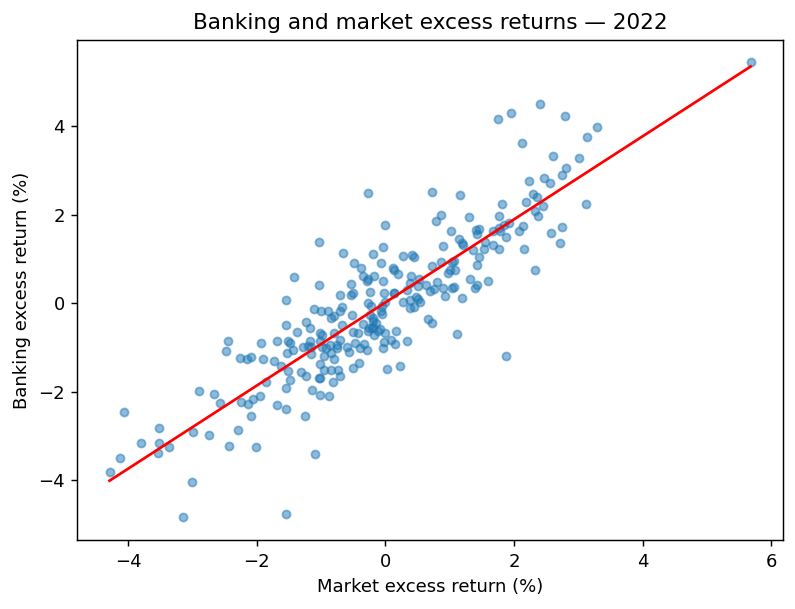

In [19]:
fig, ax = plt.subplots(figsize=(7, 5))

ax.scatter(100 * x, 100 * y, alpha=0.5, s=20)

x_line = np.array([x.min(), x.max()])
y_line = alpha_hat + beta_hat * x_line

ax.plot(100 * x_line, 100 * y_line, color="red")

ax.set_xlabel("Market excess return (%)")
ax.set_ylabel("Banking excess return (%)")
ax.set_title("Banking and market excess returns — 2022")

plt.show()

In [20]:
sse=np.sum(residuals**2)
sst=np.sum(y_centered**2)
r_squared=1-(sse/sst)
print(f"Reduction in squared error: {r_squared:.2%}")


Reduction in squared error: 75.66%


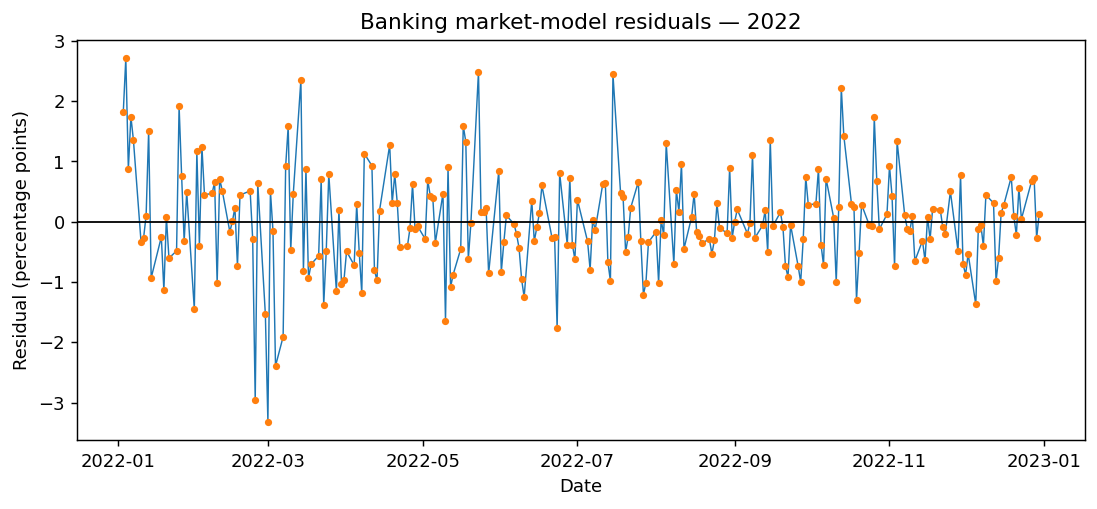

In [21]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(estimation.index, 100 * residuals, linewidth=0.8)
ax.plot(
    estimation.index,
    100 * residuals,
    marker=".",
    linestyle="none"
)
ax.axhline(0, color="black", linewidth=1)

ax.set_xlabel("Date")
ax.set_ylabel("Residual (percentage points)")
ax.set_title("Banking market-model residuals — 2022")

plt.show()

In [22]:
residual_series = pd.Series(residuals, index=estimation.index)
residual_series.head()
print("Lag-1 residual correlation:",
      residual_series.autocorr(lag=1))

print("Lag-1 squared-residual correlation:",
      (residual_series**2).autocorr(lag=1))

Lag-1 residual correlation: 0.07692943571573273
Lag-1 squared-residual correlation: 0.095005960689106


In [23]:
AR_t=y-fitted
z=AR_t/residual_std


In [24]:
def threshold_detector(z, threshold=1):
    bool_a=np.array(z<=-threshold)
    return bool_a

In [25]:
#test_run
z_example = np.array([0.4, -1.1, -2.6, -3.2, 0.3, -3.0])

flags = threshold_detector(z_example, threshold=3.0)
print(flags)

[False False False  True False  True]


In [26]:
#test code
# def cusum(zt, k, h):
#     St = 0
#     t_days = np.array([], dtype=int)

#     for i in range(len(zt)):
#         St = max(0, St - zt[i] - k)

#         if St >= h:
#             t_days = np.append(t_days, i)

#     return t_days

In [27]:
def cusum(zt, k, h, return_scores=False):
    St = 0.0
    t_days = []
    scores = np.zeros(len(zt))
    for i in range(len(zt)):
        St = max(0.0, St - zt[i] - k)
        scores[i] = St
        if St >= h:
            t_days.append(i)
            St = 0.0

    alarm_days = np.array(t_days, dtype=int)

    if return_scores:
        return alarm_days, scores

    return alarm_days

In [28]:
#test run
z_example = np.array([-1.2, -1.2, -1.2, -1.2,-1.2,-1.2, 2.0])

print(cusum(z_example, k=0.5, h=2.0))

[2 5]


In [29]:
#normal distribution test run
np.random.seed(42)

z_null = np.random.normal(loc=0.0, scale=1.0, size=81)

threshold_flags = threshold_detector(z_null, threshold=3.0)
cusum_days = cusum(z_null, k=0.5, h=2.0)

print("Threshold triggered:", threshold_flags.any())
print("CUSUM triggered:", len(cusum_days) > 0)
#Result:cusum got at least one false allarm during the simulation

Threshold triggered: False
CUSUM triggered: True


In [30]:
np.random.seed(42)

n_simulations = 1000
n_days = 81

threshold_count = 0
cusum_count = 0

for simulation in range(n_simulations):
    z_null = np.random.normal(loc=0.0, scale=1.0, size=n_days)

    if len(cusum(z_null, k=0.5, h=2.0)) >= 1:
        cusum_count += 1

    if sum(threshold_detector(z_null, threshold=3.0)) >= 1:
        threshold_count += 1
p_hat_cus=cusum_count/n_simulations
p_hat_thr=threshold_count/n_simulations

print("probability of false allarm cusum:",p_hat_cus)
print("probability of false allarm threshold:",p_hat_thr)

#results:cusum far too sensitive

probability of false allarm cusum: 0.873
probability of false allarm threshold: 0.111


In [31]:
def estimate_false_alarm_rates(
    n_simulations, n_days, threshold, k, h
):
    threshold_count = 0
    cusum_count = 0

    for simulation in range(n_simulations):
        z_null = np.random.normal(loc=0.0, scale=1.0, size=n_days)

        if len(cusum(z_null, k=k, h=h)) >= 1:
            cusum_count += 1

        if sum(threshold_detector(z_null, threshold=threshold)) >= 1:
            threshold_count += 1
    p_hat_cus=cusum_count/n_simulations
    p_hat_thr=threshold_count/n_simulations

    return p_hat_thr,p_hat_cus

np.random.seed(42)

print(estimate_false_alarm_rates(
    n_simulations=1000,
    n_days=81,
    threshold=3.0,
    k=0.5,
    h=2.0
))


(0.111, 0.873)


In [32]:
#controlled test
np.random.seed(42)
rates_a = estimate_false_alarm_rates(
    1000, 81, threshold=3.0, k=0.5, h=2.0
)

np.random.seed(123)
rates_b = estimate_false_alarm_rates(
    100000, 81, threshold=3.22, k=0.5, h=5.45
)

print(rates_a)
print(rates_b)

(0.111, 0.873)
(0.05077, 0.05086)


In [33]:
np.random.seed(2026)

change_index = 40
z_change = np.random.normal(loc=0.0, scale=1.0, size=81)
print(z_change)
z_change[change_index:] -= 1.0
print(z_change)

[-0.43171852 -1.39287397  0.31157067 -0.01323488  1.44970773  0.29815274
 -0.82989603 -1.59615853  0.6134378  -0.31759712 -0.07399665 -0.6086309
 -1.99987301  0.90824069  0.48297993  0.22187845  0.66402918 -1.24580681
  1.96887907 -0.31864893  0.3597679   0.74617104 -2.72485907  1.67537886
  0.0562327  -1.69924546 -0.36135709  2.72975002 -0.23884901 -1.42395841
 -0.16490147  0.38537238 -0.62036584 -0.60293246  1.18107553  0.83370308
 -0.00587361 -0.06904386  0.14635386 -0.4333855  -0.01012728  0.1365157
  1.47676095 -1.16648036  0.94003573  1.67279158 -0.85689767  0.18598594
  0.25180694 -0.16220392 -0.4782721  -0.99973132 -2.21205079  0.5741506
 -3.27252446  0.50971352  0.9148913  -1.03293497  0.56283625  0.71506776
  0.71620269 -0.4445134   0.35031344  0.20248679 -0.80759507 -0.52655667
  0.64929206 -0.54020778  0.45064079  0.09471285 -0.23424746  0.1145944
  0.34116998  0.07235744  0.18324503  0.69218428 -0.16390566  0.21526878
 -0.18879935  0.41566825 -0.11179755]
[-0.43171852 -1.3

### Earlier learning experiment (not part of the final analysis)

This example counts any alarm over the whole simulated path, including alarms before the change. It uses exploratory detector settings and is retained only as a learning note. The final experiment below measures post-change detection and conditional delay.

```python
#----------------------------------------------------------------------------------------------------------#
#NON CODING CELL_JUST TO UNDERSTAND THE LOGIC

def estimate_false_alarm_rates_change(
    n_simulations, n_days, threshold, k, h,
):
    threshold_count = 0
    cusum_count = 0

    for simulation in range(n_simulations):
        z_change = np.random.normal(loc=0.0, scale=1.0, size=81)

        z_change[change_index:] -= 1.0
        if len(cusum(z_change, k=k, h=h)) >= 1:
            cusum_count += 1

        if sum(threshold_detector(z_change, threshold=threshold)) >= 1:
            threshold_count += 1
    p_hat_cus=cusum_count/n_simulations
    p_hat_thr=threshold_count/n_simulations

    return p_hat_thr,p_hat_cus

np.random.seed(42)

print(estimate_false_alarm_rates_change(
    n_simulations=1000,
    n_days=81,
    threshold=3.0,
    k=0.5,
    h=2.0
))
```


In [35]:
#----------------------------------------------------------------------------------------------------------#
#NON CODING CELL_JUST TO UNDERSTAND THE LOGIC
# threshold_flags = threshold_detector(z_change, threshold=3.22)
# threshold_days = np.flatnonzero(threshold_flags)

# cusum_days = cusum(z_change, k=0.5, h=5.45)
# threshold_after = threshold_days[threshold_days >= change_index]
# if len(threshold_after)>=1:
#     threshold_delay=threshold_after[0]-change_index
# else:
#     threshold_delay=np.nan

# cusum_after = cusum_days[cusum_days >= change_index]
# if len(cusum_after)>0:
#     cusum_delay=cusum_after[0]-change_index
# else:
#     cusum_delay=np.nan
# print("Threshold alarm indices:", threshold_days)
# print("CUSUM alarm indices:", cusum_days)
# print(threshold_delay)
# print(cusum_delay)

In [36]:
def first_detection_delay(alarm_days, change_index):
    alarms_after = alarm_days[alarm_days >= change_index]

    if len(alarms_after) > 0:
        return alarms_after[0] - change_index

    return np.nan


threshold_flags = threshold_detector(z_change, threshold=3.22)
threshold_days = np.flatnonzero(threshold_flags)

cusum_days = cusum(z_change, k=0.5, h=5.45)

threshold_delay = first_detection_delay(threshold_days, change_index)
cusum_delay = first_detection_delay(cusum_days, change_index)

print("Threshold delay:", threshold_delay)
print("CUSUM delay:", cusum_delay)

Threshold delay: 14
CUSUM delay: 12


In [37]:
def evaluate_mean_shift(
    n_simulations, n_days, change_index, shift, threshold, k, h
):
    threshold_delays = np.full(n_simulations, np.nan)
    cusum_delays = np.full(n_simulations, np.nan)

    for simulation in range(n_simulations):
        z_change = np.random.normal(loc=0.0, scale=1.0, size=n_days)
        z_change[change_index:] -= shift

        threshold_flags = threshold_detector(z_change, threshold=threshold)
        threshold_days = np.flatnonzero(threshold_flags)

        cusum_days = cusum(z_change, k=k, h=h)

        threshold_delay = first_detection_delay(threshold_days, change_index)
        cusum_delay = first_detection_delay(cusum_days, change_index)

        threshold_delays[simulation] = threshold_delay
        cusum_delays[simulation] = cusum_delay

    return threshold_delays, cusum_delays

In [38]:
np.random.seed(2026)
c=evaluate_mean_shift(n_simulations=1000, n_days=81, change_index=40, shift=1, threshold=3.22, k=0.5, h=5.45)
print(c[0][:10])
print(c[1][:10])

# threshold_delays, cusum_delays = c

# print(threshold_delays[:10])
# print(cusum_delays[:10])

[14. nan  7. nan nan nan 24. 27. nan nan]
[12. 22.  6.  2.  5.  2.  5. 37. 12. 12.]


In [39]:
#ACCEPTS ONE DETECTOR’S DELAY ARRAY AND RETURNS A DICTIONARY: VALUES IDENTIFIED BY DESCRIPTIVE NAMES.
def summarize_detection(delays):
    detected = ~np.isnan(delays)

    detection_probability = detected.mean()

    if detected.any():
        mean_delay = delays[detected].mean()
    else:
        mean_delay = np.nan

    return {
        "detection_probability": detection_probability,
        "mean_delay_if_detected": mean_delay
    }
#RETURNS A DICTIONARY

In [40]:
threshold_delays, cusum_delays = c

threshold_summary = summarize_detection(threshold_delays)
cusum_summary = summarize_detection(cusum_delays)

print(threshold_summary)
print(cusum_summary)
#RESULT:cusum performs substantially better in this instance

{'detection_probability': np.float64(0.41), 'mean_delay_if_detected': np.float64(17.878048780487806)}
{'detection_probability': np.float64(0.999), 'mean_delay_if_detected': np.float64(9.472472472472472)}


In [41]:
#DOES DIFFERENCE BTW 2 DETECTOR PERSIST VARYING SHIFT IN MAGNITUDE?
shift_results = {}

for shift in [0.25, 0.5, 1.0, 1.5, 2.0]:
    np.random.seed(2026)

    threshold_delays, cusum_delays = evaluate_mean_shift(
        n_simulations=1000,
        n_days=81,
        change_index=40,
        shift=shift,
        threshold=3.22,
        k=0.5,
        h=5.45
    )

    shift_results[shift] = {
        "threshold": summarize_detection(threshold_delays),
        "cusum": summarize_detection(cusum_delays)
    }

for shift, summaries in shift_results.items():
    print("Shift:", shift)
    print("Threshold:", summaries["threshold"])
    print("CUSUM:", summaries["cusum"])

Shift: 0.25
Threshold: {'detection_probability': np.float64(0.075), 'mean_delay_if_detected': np.float64(21.893333333333334)}
CUSUM: {'detection_probability': np.float64(0.171), 'mean_delay_if_detected': np.float64(21.608187134502923)}
Shift: 0.5
Threshold: {'detection_probability': np.float64(0.145), 'mean_delay_if_detected': np.float64(20.103448275862068)}
CUSUM: {'detection_probability': np.float64(0.626), 'mean_delay_if_detected': np.float64(19.599041533546327)}
Shift: 1.0
Threshold: {'detection_probability': np.float64(0.41), 'mean_delay_if_detected': np.float64(17.878048780487806)}
CUSUM: {'detection_probability': np.float64(0.999), 'mean_delay_if_detected': np.float64(9.472472472472472)}
Shift: 1.5
Threshold: {'detection_probability': np.float64(0.809), 'mean_delay_if_detected': np.float64(13.714462299134734)}
CUSUM: {'detection_probability': np.float64(1.0), 'mean_delay_if_detected': np.float64(4.698)}
Shift: 2.0
Threshold: {'detection_probability': np.float64(0.987), 'mean_del

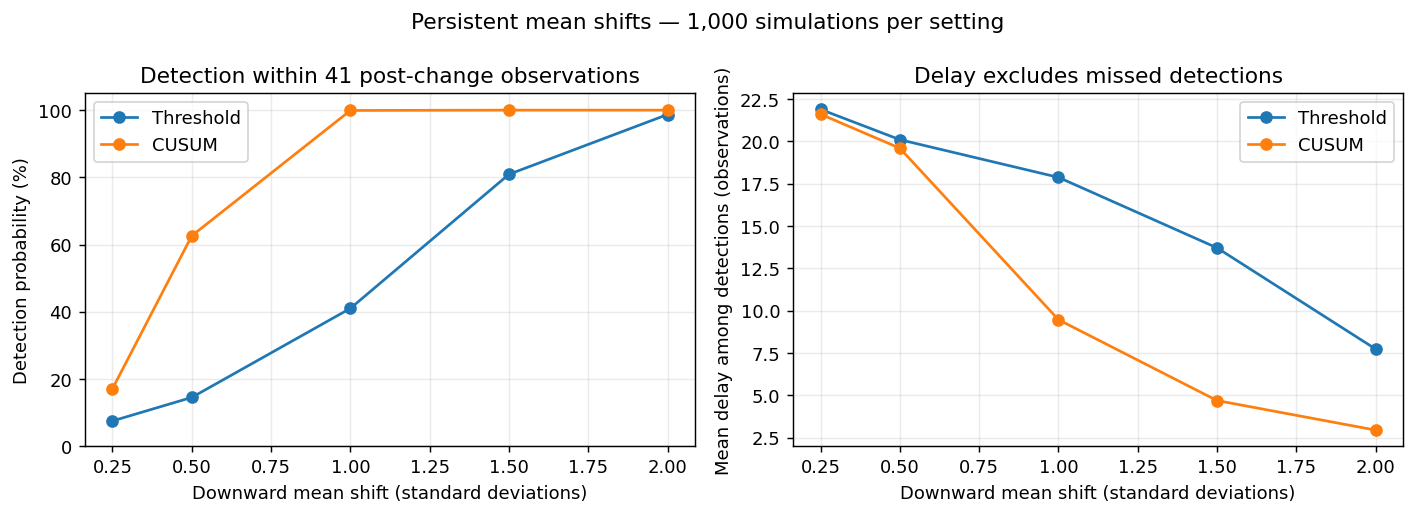

In [42]:
#REPRESENTATIVE PANEL
shifts = sorted(shift_results)

fig, axes = plt.subplots(figsize=(11, 4), nrows=1, ncols=2)

for method, label in [
    ("threshold", "Threshold"),
    ("cusum", "CUSUM")
]:
    probabilities = [
        shift_results[s][method]["detection_probability"]
        for s in shifts
    ]

    delays = [
        shift_results[s][method]["mean_delay_if_detected"]
        for s in shifts
    ]

    axes[0].plot(
        shifts, 100 * np.array(probabilities),
        marker="o", label=label
    )

    axes[1].plot(
        shifts, delays,
        marker="o", label=label
    )

axes[0].set_ylabel("Detection probability (%)")
axes[0].set_ylim(0, 105)
axes[0].set_title("Detection within 41 post-change observations")

axes[1].set_ylabel("Mean delay among detections (observations)")
axes[1].set_title("Delay excludes missed detections")

for ax in axes:
    ax.set_xlabel("Downward mean shift (standard deviations)")
    ax.legend()
    ax.grid(alpha=0.25)

fig.suptitle("Persistent mean shifts — 1,000 simulations per setting")
fig.tight_layout()
plt.show()


In [43]:
def evaluate_isolated_shock(
    n_simulations, n_days, shock_index, shock_size, threshold, k, h
):
    threshold_hits = np.zeros(n_simulations, dtype=bool)
    cusum_hits = np.zeros(n_simulations, dtype=bool)

    for simulation in range(n_simulations):
        z_shock = np.random.normal(loc=0.0, scale=1.0, size=n_days)
        z_shock[shock_index] -= shock_size

        # Run  threshold detector and CUSUM.
        threshold_flags = threshold_detector(z_shock, threshold=threshold)
        #threshold_days = np.flatnonzero(threshold_flags)

        cusum_days = cusum(z_shock, k=k, h=h)

        # Store whether each detector alarms exactly at shock_index.
        threshold_hits[simulation] = threshold_flags[shock_index]
        cusum_hits[simulation] = shock_index in cusum_days


    return threshold_hits, cusum_hits

In [44]:
np.random.seed(2026)

threshold_hits, cusum_hits = evaluate_isolated_shock(
    n_simulations=1000,
    n_days=81,
    shock_index=40,
    shock_size=3.0,
    threshold=3.22,
    k=0.5,
    h=5.45
)

shock_summary = {
    "threshold": threshold_hits.mean(),
    "cusum": cusum_hits.mean()
}

print(shock_summary)

{'threshold': np.float64(0.418), 'cusum': np.float64(0.041)}


In [45]:
#CONTROLLED EXPERIMENT
shock_results = {}

for shock_size in [0.0, 1.0, 2.0, 3.0, 4.0, 5.0]:
    np.random.seed(2026)

    threshold_hits, cusum_hits = evaluate_isolated_shock(
        n_simulations=1000,
        n_days=81,
        shock_index=40,
        shock_size=shock_size,
        threshold=3.22,
        k=0.5,
        h=5.45
    )

    shock_results[shock_size] = {
        "threshold": threshold_hits.mean(),
        "cusum": cusum_hits.mean()
    }

for shock_size, results in shock_results.items():
    print(shock_size, results)

0.0 {'threshold': np.float64(0.0), 'cusum': np.float64(0.002)}
1.0 {'threshold': np.float64(0.015), 'cusum': np.float64(0.003)}
2.0 {'threshold': np.float64(0.114), 'cusum': np.float64(0.02)}
3.0 {'threshold': np.float64(0.418), 'cusum': np.float64(0.041)}
4.0 {'threshold': np.float64(0.8), 'cusum': np.float64(0.132)}
5.0 {'threshold': np.float64(0.966), 'cusum': np.float64(0.328)}


In [46]:
def evaluate_volatility_change(
    n_simulations, n_days, change_index,
    volatility_multiplier, threshold, k, h
):
    threshold_delays = np.full(n_simulations, np.nan)
    cusum_delays = np.full(n_simulations, np.nan)

    for simulation in range(n_simulations):
        z_change = np.random.normal(loc=0.0, scale=1.0, size=n_days)
        z_change[change_index:] *= volatility_multiplier

        threshold_flags = threshold_detector(z_change, threshold=threshold)
        threshold_days = np.flatnonzero(threshold_flags)

        cusum_days = cusum(z_change, k=k, h=h)

        threshold_delay = first_detection_delay(threshold_days, change_index)
        cusum_delay = first_detection_delay(cusum_days, change_index)

        threshold_delays[simulation] = threshold_delay
        cusum_delays[simulation] = cusum_delay

    return threshold_delays, cusum_delays

In [47]:
np.random.seed(2026)

threshold_vol_delays, cusum_vol_delays = evaluate_volatility_change(
    n_simulations=1000,
    n_days=81,
    change_index=40,
    volatility_multiplier=2.0,
    threshold=3.22,
    k=0.5,
    h=5.45
)

volatility_summary = {
    "threshold": summarize_detection(threshold_vol_delays),
    "cusum": summarize_detection(cusum_vol_delays)
}

print(volatility_summary)

{'threshold': {'detection_probability': np.float64(0.877), 'mean_delay_if_detected': np.float64(12.513112884834664)}, 'cusum': {'detection_probability': np.float64(0.732), 'mean_delay_if_detected': np.float64(16.21311475409836)}}


In [48]:
volatility_results = {}

for multiplier in [1.0, 1.25, 1.5, 2.0]:
    np.random.seed(2026)

    threshold_delays, cusum_delays = evaluate_volatility_change(
        n_simulations=1000,
        n_days=81,
        change_index=40,
        volatility_multiplier=multiplier,
        threshold=3.22,
        k=0.5,
        h=5.45
    )

    volatility_results[multiplier] = {
        "threshold": summarize_detection(threshold_delays),
        "cusum": summarize_detection(cusum_delays)
    }

for multiplier, results in volatility_results.items():
    print(multiplier, results)

1.0 {'threshold': {'detection_probability': np.float64(0.036), 'mean_delay_if_detected': np.float64(22.944444444444443)}, 'cusum': {'detection_probability': np.float64(0.026), 'mean_delay_if_detected': np.float64(18.96153846153846)}}
1.25 {'threshold': {'detection_probability': np.float64(0.193), 'mean_delay_if_detected': np.float64(20.025906735751295)}, 'cusum': {'detection_probability': np.float64(0.133), 'mean_delay_if_detected': np.float64(19.796992481203006)}}
1.5 {'threshold': {'detection_probability': np.float64(0.472), 'mean_delay_if_detected': np.float64(17.358050847457626)}, 'cusum': {'detection_probability': np.float64(0.357), 'mean_delay_if_detected': np.float64(19.128851540616246)}}
2.0 {'threshold': {'detection_probability': np.float64(0.877), 'mean_delay_if_detected': np.float64(12.513112884834664)}, 'cusum': {'detection_probability': np.float64(0.732), 'mean_delay_if_detected': np.float64(16.21311475409836)}}


In [49]:
#APPLYING ALLARM FUNCTIONS TO HEAVIER TAIL FUNCTIONS(STUDENT'S T)
def estimate_false_alarm_rates_t(
    n_simulations, n_days, threshold, k, h
):
    threshold_count = 0
    cusum_count = 0

    for simulation in range(n_simulations):
        z_null = np.random.standard_t(df=5, size=n_days) * np.sqrt(3 / 5)

        if len(cusum(z_null, k=k, h=h)) >= 1:
            cusum_count += 1

        if sum(threshold_detector(z_null, threshold=threshold)) >= 1:
            threshold_count += 1
    p_hat_cus=cusum_count/n_simulations
    p_hat_thr=threshold_count/n_simulations

    return p_hat_thr,p_hat_cus


In [50]:
np.random.seed(2027)

heavy_tail_rates = estimate_false_alarm_rates_t(
    n_simulations=10000,
    n_days=81,
    threshold=3.22,
    k=0.5,
    h=5.45
)

heavy_tail_summary = {
    "threshold": heavy_tail_rates[0],
    "cusum": heavy_tail_rates[1]
}

print(heavy_tail_summary)

{'threshold': 0.2951, 'cusum': 0.0915}


In [51]:
# standardized residual pool
z_pre = residuals / residual_std

np.random.seed(2028)

block_length = 5 #APPROXIMATELY ONE TRADING WEEK
start = np.random.randint(0, len(z_pre) - block_length + 1)

block=z_pre[start:start+block_length]
print(block)

[ 1.02939314  2.05065122  1.59203993 -0.39333782 -0.31714373]


In [52]:
#ARTIFICIAL MONITORING PERIOD

def sample_residual_blocks(z_pre, n_days, block_length):
    if not 1 <= block_length <= len(z_pre):
        raise ValueError("block_length must be between 1 and the residual pool length")
    if n_days < 1:
        raise ValueError("n_days must be positive")

    sampled = []

    while len(sampled) < (n_days):

        start = np.random.randint(0, len(z_pre) - block_length + 1)

        block=z_pre[start:start+block_length]

        sampled.extend(block)
        # Choose a valid random starting index.

        # Extract one consecutive block.

        # Add its individual values to sampled.

    return np.array(sampled[:n_days])


In [53]:
np.random.seed(2028)

z_boot = sample_residual_blocks(
    z_pre, n_days=81, block_length=5
)

print("Length:", len(z_boot))
print("First block:", z_boot[:5])

Length: 81
First block: [ 1.02939314  2.05065122  1.59203993 -0.39333782 -0.31714373]


In [54]:
def estimate_bootstrap_false_alarm_rates(
    z_pre, block_length, n_simulations, n_days, threshold, k, h
):

    threshold_count = 0
    cusum_count = 0

    for simulation in range(n_simulations):
        z_null = sample_residual_blocks(z_pre, n_days, block_length)

        if len(cusum(z_null, k=k, h=h)) >= 1:
            cusum_count += 1

        if sum(threshold_detector(z_null, threshold=threshold)) >= 1:
            threshold_count += 1
    p_hat_cus=cusum_count/n_simulations
    p_hat_thr=threshold_count/n_simulations

    return p_hat_thr,p_hat_cus

In [55]:
detector_bootstrap_results = {}

for block_length in [1, 5]:
    np.random.seed(2028)

    rates = estimate_bootstrap_false_alarm_rates(
        z_pre=z_pre,
        block_length=block_length,
        n_simulations=10000,
        n_days=81,
        threshold=3.22,
        k=0.5,
        h=5.45
    )

    detector_bootstrap_results[block_length] = {
        "threshold": rates[0],
        "cusum": rates[1]
    }

print(detector_bootstrap_results)

{1: {'threshold': 0.4724, 'cusum': 0.07}, 5: {'threshold': 0.4186, 'cusum': 0.2468}}


In [56]:
extreme_count = np.sum(z_pre <= -3.22)
q = extreme_count / len(z_pre)

expected_rate = 1 - (1 - q)**81

print("Residuals below the cutoff:", extreme_count)
print("Expected rate under independent resampling:", expected_rate)

Residuals below the cutoff: 2
Expected rate under independent resampling: 0.4769108947139258


In [57]:
historical = monitoring.copy()

historical["Expected_excess"] = (
    alpha_hat + beta_hat * historical["Mkt-RF"]
)

historical["Abnormal_return"] = (
    historical["Banks-RF"] - historical["Expected_excess"]
)

historical["z"] = historical["Abnormal_return"] / residual_std

historical[
    ["Banks-RF", "Expected_excess", "Abnormal_return", "z"]
].head()

,Banks-RF,Expected_excess,Abnormal_return,z
Date,,,,
2023-01-03,0.0023,-0.004252,0.006552,0.770425
2023-01-04,0.0183,0.007763,0.010537,1.238957
2023-01-05,-0.0088,-0.010542,0.001742,0.204774
2023-01-06,0.0256,0.020904,0.004696,0.552103
2023-01-09,-0.0023,0.000441,-0.002741,-0.322292


In [58]:
z_2023 = historical["z"].to_numpy()

historical_threshold_flags = threshold_detector(
    z_2023, threshold=3.22
)

historical_cusum_indices = cusum(
    z_2023, k=0.5, h=5.45
)

In [59]:
threshold_dates = historical.index[historical_threshold_flags]
cusum_dates = historical.index[historical_cusum_indices]

historical_alarm_dates = {
    "threshold": threshold_dates,
    "cusum": cusum_dates
}

print("Threshold alarm dates:")
print(threshold_dates)

print("CUSUM alarm dates:")
print(cusum_dates)

Threshold alarm dates:
DatetimeIndex(['2023-03-09', '2023-03-13'], dtype='datetime64[ns]', name='Date', freq=None)
CUSUM alarm dates:
DatetimeIndex(['2023-03-13'], dtype='datetime64[ns]', name='Date', freq=None)


In [60]:
event_detail = historical.loc[
    "2023-03-06":"2023-03-15",
    ["Banks-RF", "Expected_excess", "Abnormal_return", "z"]
].copy()

event_detail["Threshold_alarm"] = event_detail.index.isin(threshold_dates)
event_detail["CUSUM_alarm"] = event_detail.index.isin(cusum_dates)

event_detail

,Banks-RF,Expected_excess,Abnormal_return,z,Threshold_alarm,CUSUM_alarm
Date,,,,,,
2023-03-06,-0.0007,-0.001061,0.000361,0.042427,False,False
2023-03-07,-0.0281,-0.013452,-0.014648,-1.722363,False,False
2023-03-08,-0.0060,0.000910,-0.006910,-0.812522,False,False
2023-03-09,-0.0462,-0.018802,-0.027398,-3.221442,True,False
2023-03-10,-0.0176,-0.015610,-0.001990,-0.233926,False,False
2023-03-13,-0.0522,-0.003032,-0.049168,-5.781141,True,True
2023-03-14,0.0249,0.016305,0.008595,1.010612,False,False
2023-03-15,-0.0244,-0.007256,-0.017144,-2.015763,False,False


In [61]:
historical_cusum_indices, historical_cusum_scores = cusum(
    z_2023, k=0.5, h=5.45, return_scores=True
)

historical["CUSUM_score"] = historical_cusum_scores

historical.loc[
    "2023-03-06":"2023-03-15",
    ["z", "CUSUM_score"]
]

,z,CUSUM_score
Date,,
2023-03-06,0.042427,0.012087
2023-03-07,-1.722363,1.234450
2023-03-08,-0.812522,1.546972
2023-03-09,-3.221442,4.268414
2023-03-10,-0.233926,4.002340
2023-03-13,-5.781141,9.283481
2023-03-14,1.010612,0.000000
2023-03-15,-2.015763,1.515763


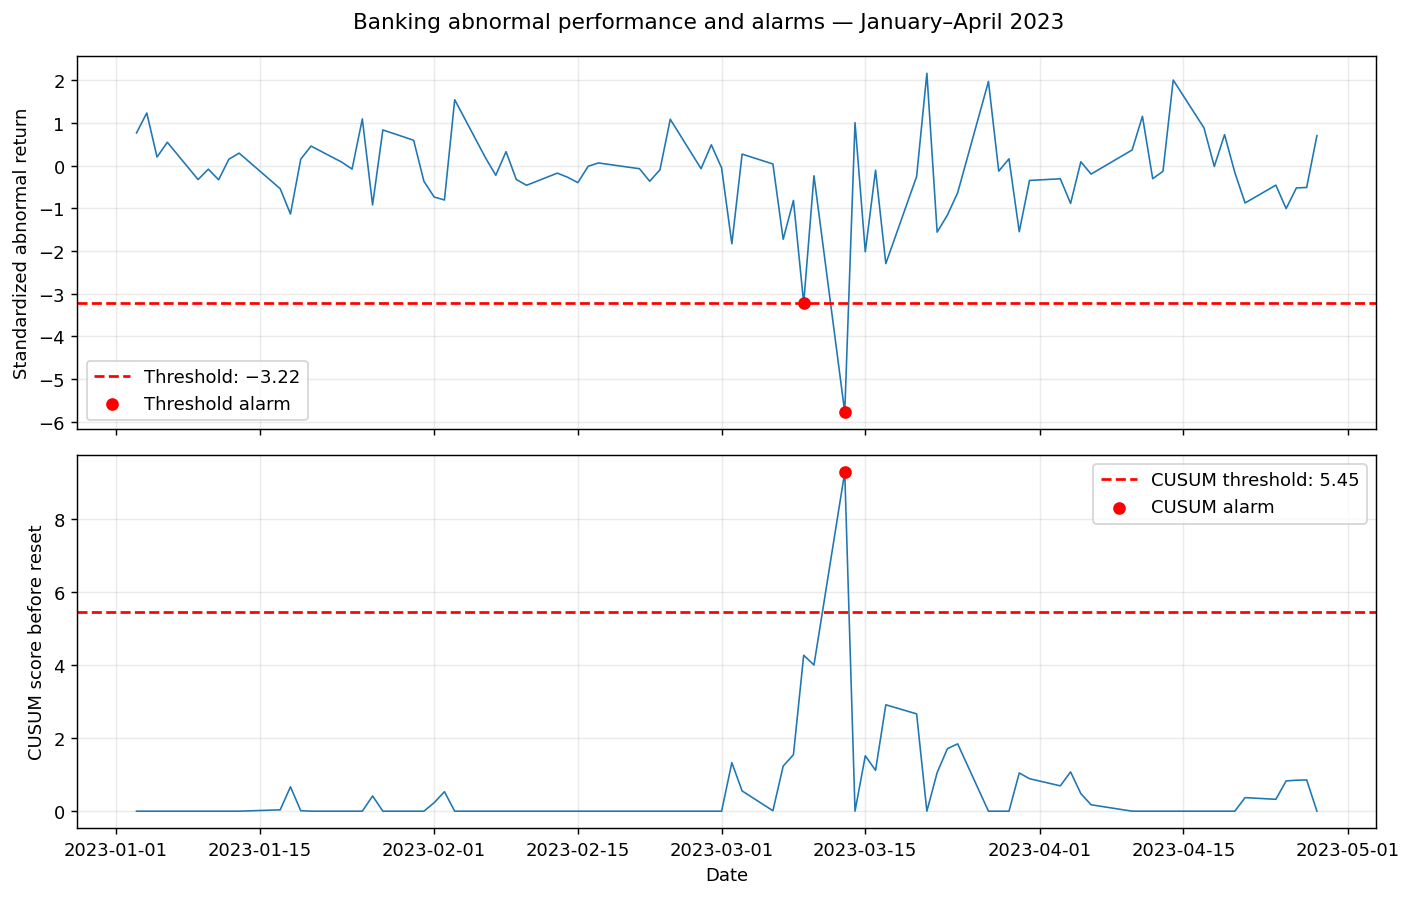

In [62]:
fig, axes = plt.subplots(2, 1, figsize=(11, 7), sharex=True)

axes[0].plot(historical.index, historical["z"], linewidth=0.9)
axes[0].axhline(-3.22, color="red", linestyle="--",
                label="Threshold: −3.22")
axes[0].scatter(
    threshold_dates,
    historical.loc[threshold_dates, "z"],
    color="red", zorder=3, label="Threshold alarm"
)
axes[0].set_ylabel("Standardized abnormal return")
axes[0].legend()

axes[1].plot(
    historical.index, historical["CUSUM_score"], linewidth=0.9
)
axes[1].axhline(5.45, color="red", linestyle="--",
                label="CUSUM threshold: 5.45")
axes[1].scatter(
    cusum_dates,
    historical.loc[cusum_dates, "CUSUM_score"],
    color="red", zorder=3, label="CUSUM alarm"
)
axes[1].set_ylabel("CUSUM score before reset")
axes[1].set_xlabel("Date")
axes[1].legend()

for ax in axes:
    ax.grid(alpha=0.25)

fig.suptitle("Banking abnormal performance and alarms — January–April 2023")
fig.tight_layout()
plt.show()

In [63]:
pre_stress = historical.loc["2023-01-03":"2023-03-07"]
stress = historical.loc["2023-03-08":"2023-03-31"]
post_stress = historical.loc["2023-04-01":"2023-04-28"]

In [64]:
def summarize_window(data):
    return pd.Series({
        "n_days": len(data),
        "mean_abnormal_return_pct":
            100 * data["Abnormal_return"].mean(),
        "cumulative_abnormal_return_pct":
            100 * data["Abnormal_return"].sum(),
        "abnormal_volatility_pct":
            100 * data["Abnormal_return"].std(ddof=1),
        "minimum_z":
            data["z"].min(),
        "minimum_z_date":
            data["z"].idxmin()
    })

In [65]:
window_summary = pd.DataFrame({
    "Pre-stress": summarize_window(pre_stress),
    "Stress": summarize_window(stress),
    "Post-stress": summarize_window(post_stress)
}).T

window_summary

,n_days,mean_abnormal_return_pct,cumulative_abnormal_return_pct,abnormal_volatility_pct,minimum_z,minimum_z_date
Pre-stress,44,-0.016104,-0.70856,0.582435,-1.828203,2023-03-02 00:00:00
Stress,18,-0.696932,-12.544769,1.573151,-5.781141,2023-03-13 00:00:00
Post-stress,19,0.027828,0.528732,0.661268,-1.003961,2023-04-25 00:00:00


In [66]:
#IS HIGH AVERAGE ABNORMAL RETURN IN STRESS PERIOD SPREAD ACROSS OR LARGELY DRIVEN BY MARCH 9 AND 13?

stress_ar = stress["Abnormal_return"]

# Descriptive check: exclude the two historical threshold-alarm dates.
remaining_ar = stress_ar.drop(
    pd.to_datetime(["2023-03-09", "2023-03-13"])
)

stress_concentration = pd.Series({
    "median_daily_abnormal_pct": 100 * stress_ar.median(),
    "negative_days": (stress_ar < 0).sum(),
    "total_days": len(stress_ar),
    "two_alarm_days_sum_pct":
        100 * (stress_ar.sum() - remaining_ar.sum()),
    "remaining_days_sum_pct": 100 * remaining_ar.sum(),
    "remaining_days_mean_pct": 100 * remaining_ar.mean()
})

stress_concentration

median_daily_abnormal_pct    -0.414939
negative_days                14.000000
total_days                   18.000000
two_alarm_days_sum_pct       -7.656590
remaining_days_sum_pct       -4.888179
remaining_days_mean_pct      -0.305511
dtype: float64

In [67]:
historical["CAR"] = historical["Abnormal_return"].cumsum()

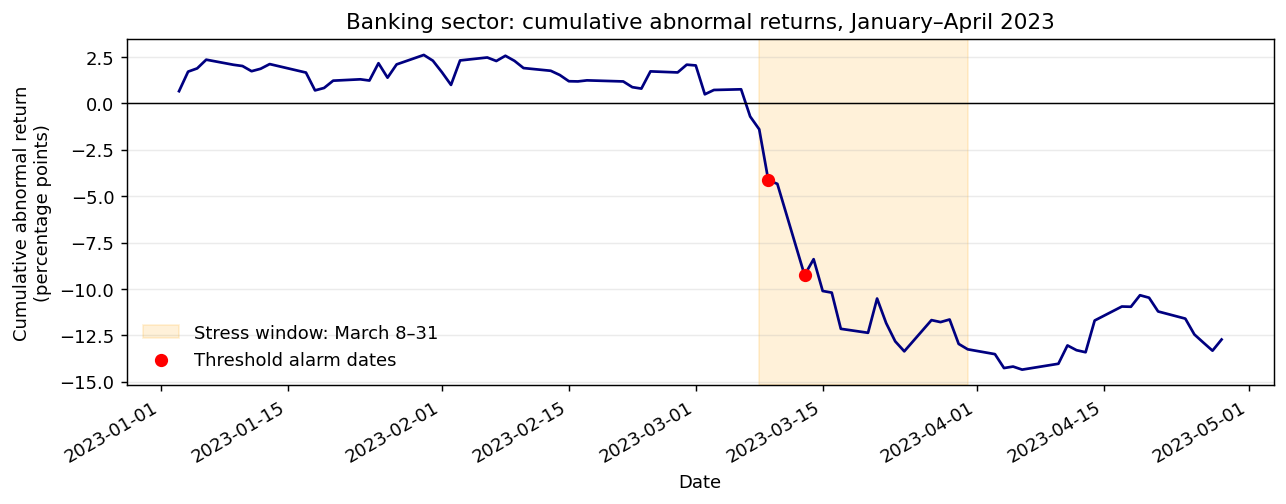

In [68]:
fig, ax = plt.subplots(figsize=(10, 4))

ax.plot(
    historical.index,
    100 * historical["CAR"],
    color="navy",
    linewidth=1.5
)

ax.axhline(0, color="black", linewidth=0.8)

ax.axvspan(
    pd.Timestamp("2023-03-08"),
    pd.Timestamp("2023-03-31"),
    color="orange",
    alpha=0.15,
    label="Stress window: March 8–31"
)

alarm_dates = threshold_dates

ax.scatter(
    alarm_dates,
    100 * historical.loc[alarm_dates, "CAR"],
    color="red",
    s=40,
    zorder=3,
    label="Threshold alarm dates"
)

ax.set(
    title="Banking sector: cumulative abnormal returns, January–April 2023",
    xlabel="Date",
    ylabel="Cumulative abnormal return\n(percentage points)"
)

ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.25)
fig.autofmt_xdate()
fig.tight_layout()

plt.show()

In [69]:
def find(parent, v):
    root = v

    # First pass: discover the root.
    while parent[root] != root:
        root = parent[root]

    # Second pass: redirect the original path to the root.
    while parent[v] != v:
        next_vertex = parent[v]

        # Make v point directly to root.
        parent[v]=root
        # Move v to next_vertex.
        v=next_vertex
    return root

In [70]:
parent = list(range(4))
print(parent)
size = [1] * 4
print(size)

[0, 1, 2, 3]
[1, 1, 1, 1]


In [71]:
def union(parent, size, a, b):
    root_a = find(parent, a)
    root_b = find(parent, b)

    if root_a == root_b:
       return False

    # Make root_a the root of the larger component.
    if size[root_a] < size[root_b]:
        root_a, root_b = root_b, root_a

    # Attach root_b to root_a.
    parent[root_b]=parent[root_a]#parent[root_b] = root_a
    # Increase the size recorded at root_a.
    size[root_a]+=size[root_b]

    return True

In [72]:
connected = union(parent, size, 0, 1)

if connected:
    print("The components have been connected.")
else:
    print("The components are already connected.")
print(union(parent, size, 1, 2))  # True
print(union(parent, size, 0, 2))  # False: already connected

print(parent)  # [0, 0, 0, 3]
print(size)    # [3, 1, 1, 1]

The components have been connected.
True
False
[0, 0, 0, 3]
[3, 1, 1, 1]


In [73]:
def kruskal(n_vertices, edges):
    parent = list(range(n_vertices))
    size = [1] * n_vertices

    sorted_edges = sorted(edges, key=lambda edge: edge[2])

    mst_edges = []

    for a, b, weight in sorted_edges:
        # Try to merge the components containing a and b.
        if union(parent,size,a,b):
            mst_edges.append((a,b,weight))
        # If the merge succeeds, save this edge.
        if len(mst_edges)==n_vertices-1:
            break
        # Stop once the MST has n_vertices - 1 edges.

    return mst_edges

In [74]:
edges = [
    (0, 1, 1.0),
    (1, 2, 2.0),
    (0, 2, 3.0),
    (2, 3, 1.5),
    (1, 3, 4.0)
]

mst = kruskal(n_vertices=4, edges=edges)
print(mst)
print("Total weight:", sum(edge[2] for edge in mst))

[(0, 1, 1.0), (2, 3, 1.5), (1, 2, 2.0)]
Total weight: 4.5


In [75]:
industries = [
    "Banks", "Insur", "RlEst", "Fin",
    "Softw", "Chips",
    "Util", "Oil",
    "Mach", "Trans",
    "Rtail", "Food"
]

In [76]:
network_returns = returns.loc[:, industries].copy()

network_windows = {
    "February": network_returns.loc["2023-02-01":"2023-02-28"],
    "March": network_returns.loc["2023-03-01":"2023-03-31"],
    "April": network_returns.loc["2023-04-01":"2023-04-28"]
}

for month, data in network_windows.items():
    print(
        month,
        "shape:", data.shape,
        "missing values:", data.isna().sum().sum()
    )

February shape: (19, 12) missing values: 0
March shape: (23, 12) missing values: 0
April shape: (19, 12) missing values: 0


In [77]:
corr_feb = network_windows["February"].corr()

corr_feb.loc[["Banks", "Insur", "RlEst"], ["Banks", "Insur", "RlEst"]]

,Banks,Insur,RlEst
Banks,1.000000,0.141175,0.718036
Insur,0.141175,1.000000,-0.131492
RlEst,0.718036,-0.131492,1.000000


In [78]:
def correlation_to_edges(correlation_matrix):
    values = correlation_matrix.to_numpy()
    if not np.all(np.isfinite(values)):
        raise ValueError("Correlations must be finite; check missing or constant columns")
    if np.any(np.abs(values) > 1 + 1e-12):
        raise ValueError("Correlations must lie between -1 and 1")

    node_names = list(correlation_matrix.columns)
    edges = []

    for i in range(len(node_names)):
        for j in range(i + 1, len(node_names)):
            # Extracting the correlation between columns i and j.
            rho = correlation_matrix.iloc[i, j]
            # Converting it into a distance.
            distance = np.sqrt(2 * (1 - np.clip(rho, -1, 1)))
            # Storing the edge as (i, j, distance).
            edges.append((i, j, distance))
    return node_names, edges

In [79]:
feb_names, feb_edges = correlation_to_edges(corr_feb)

print("Nodes:", feb_names)
print("Number of edges:", len(feb_edges))
print("First five edges:", feb_edges[:5])

Nodes: ['Banks', 'Insur', 'RlEst', 'Fin', 'Softw', 'Chips', 'Util', 'Oil', 'Mach', 'Trans', 'Rtail', 'Food']
Number of edges: 66
First five edges: [(0, 1, np.float64(1.3105914635933114)), (0, 2, np.float64(0.7509510110547098)), (0, 3, np.float64(0.4579013446766078)), (0, 4, np.float64(0.7425717966620327)), (0, 5, np.float64(0.5435958859385673))]


In [80]:
feb_mst = kruskal(
    n_vertices=len(feb_names),
    edges=feb_edges
)

print("MST edges:", len(feb_mst))
print(feb_mst)

MST edges: 11
[(0, 3, np.float64(0.4579013446766078)), (2, 4, np.float64(0.5258357221247794)), (4, 5, np.float64(0.5417342374629155)), (0, 5, np.float64(0.5435958859385673)), (4, 10, np.float64(0.5605563329757132)), (5, 9, np.float64(0.5690475994096648)), (0, 8, np.float64(0.6400978427262997)), (6, 11, np.float64(0.7787855945724707)), (6, 10, np.float64(0.9111128693188754)), (1, 11, np.float64(1.0287605106642068)), (1, 7, np.float64(1.140724281837317))]


In [81]:
#applying same procedure for other months
network_results = {}

for month, data in network_windows.items():
    correlation = data.corr()
    names, edges = correlation_to_edges(correlation)
    mst = kruskal(n_vertices=len(names), edges=edges)

    network_results[month] = {
        "correlation": correlation,
        "names": names,
        "mst": mst
    }

In [82]:
for month, result in network_results.items():
    names = result["names"]
    bank_index = names.index("Banks")
    bank_neighbors = []

    for a, b, distance in result["mst"]:
        if a == bank_index:
            bank_neighbors.append(names[b])
        elif b == bank_index:
            bank_neighbors.append(names[a])

    result["bank_neighbors"] = bank_neighbors
    result["bank_degree"] = len(bank_neighbors)

    print(
        month,
        "Bank degree:", result["bank_degree"],
        "Neighbours:", bank_neighbors
    )

February Bank degree: 3 Neighbours: ['Fin', 'Chips', 'Mach']
March Bank degree: 1 Neighbours: ['Fin']
April Bank degree: 1 Neighbours: ['Fin']


In [83]:
bank_correlations = pd.DataFrame({
    month: result["correlation"]["Banks"]
    for month, result in network_results.items()
}).drop(index="Banks")

bank_correlations

,February,March,April
Insur,0.141175,0.825638,0.215143
RlEst,0.718036,0.844875,0.752503
Fin,0.895163,0.893827,0.930058
Softw,0.724294,0.530472,0.401633
Chips,0.852252,0.591010,0.712439
Util,0.396891,0.307476,0.143340
Oil,0.127377,0.769525,0.365405
Mach,0.795137,0.710927,0.657641
Trans,0.795855,0.834725,0.884708
Rtail,0.569528,0.621869,0.472390


In [84]:
def mst_edge_set(result):
    names = result["names"]

    return {
        tuple(sorted((names[a], names[b])))
        for a, b, distance in result["mst"]
    }

In [85]:
edge_sets = {
    month: mst_edge_set(result)
    for month, result in network_results.items()
}

edge_overlap = {}

for first, second in [
    ("February", "March"),
    ("March", "April"),
    ("February", "April")
]:
    shared = edge_sets[first] & edge_sets[second]

    edge_overlap[f"{first}–{second}"] = {
        "shared_edges": len(shared),
        "fraction_shared": len(shared) / len(edge_sets[first])
    }

pd.DataFrame(edge_overlap).T

,shared_edges,fraction_shared
February–March,5.0,0.454545
March–April,4.0,0.363636
February–April,4.0,0.363636


In [86]:
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import (
    minimum_spanning_tree,
    connected_components
)

validation_results = {}

for month, result in network_results.items():
    n = len(result["names"])

    # Independently construct the complete distance matrix.
    rho = result["correlation"].to_numpy()
    distances = np.sqrt(2 * (1 - np.clip(rho, -1, 1)))
    np.fill_diagonal(distances, 0)

    # This matrix representation requires positive off-diagonal distances.
    off_diagonal = distances[np.triu_indices(n, k=1)]
    assert np.all(np.isfinite(off_diagonal))
    assert np.all(off_diagonal > 0)

    reference_mst = minimum_spanning_tree(csr_matrix(distances))
    reference_weight = float(reference_mst.sum())

    # Represent your selected edges for the connectivity check.
    adjacency = np.zeros((n, n))
    for a, b, weight in result["mst"]:
        adjacency[a, b] = adjacency[b, a] = 1

    components = connected_components(
        csr_matrix(adjacency),
        directed=False,
        return_labels=False
    )

    custom_weight = sum(weight for a, b, weight in result["mst"])

    validation_results[month] = {
        "edge_count": len(result["mst"]),
        "components": components,
        "custom_weight": custom_weight,
        "reference_weight": reference_weight,
        "weight_matches": np.isclose(
            custom_weight, reference_weight,
            rtol=1e-10, atol=1e-12
        )
    }

for month, check in validation_results.items():
    assert check["edge_count"] == len(network_results[month]["names"]) - 1
    assert check["components"] == 1
    assert check["weight_matches"]

pd.DataFrame(validation_results).T

,edge_count,components,custom_weight,reference_weight,weight_matches
February,11,1,7.698152,7.698152,True
March,11,1,6.159159,6.159159,True
April,11,1,7.720528,7.720528,True


In [87]:
def mst_named_edges(result):
    names = result["names"]

    return [
        (names[a], names[b], weight)
        for a, b, weight in result["mst"]
    ]

In [88]:
for month, result in network_results.items():
    print("\n", month)
    for edge in mst_named_edges(result):
        print(edge)


 February
('Banks', 'Fin', np.float64(0.4579013446766078))
('RlEst', 'Softw', np.float64(0.5258357221247794))
('Softw', 'Chips', np.float64(0.5417342374629155))
('Banks', 'Chips', np.float64(0.5435958859385673))
('Softw', 'Rtail', np.float64(0.5605563329757132))
('Chips', 'Trans', np.float64(0.5690475994096648))
('Banks', 'Mach', np.float64(0.6400978427262997))
('Util', 'Food', np.float64(0.7787855945724707))
('Util', 'Rtail', np.float64(0.9111128693188754))
('Insur', 'Food', np.float64(1.0287605106642068))
('Insur', 'Oil', np.float64(1.140724281837317))

 March
('RlEst', 'Fin', np.float64(0.4216238578184998))
('RlEst', 'Trans', np.float64(0.43263885685582776))
('Banks', 'Fin', np.float64(0.4608091154383979))
('Softw', 'Chips', np.float64(0.5408510214149602))
('Fin', 'Mach', np.float64(0.5505549553320606))
('Util', 'Food', np.float64(0.5633501789939483))
('RlEst', 'Rtail', np.float64(0.5753042009004109))
('Insur', 'RlEst', np.float64(0.5776808208318733))
('Softw', 'Rtail', np.float64(

### Monthly MST resampling sensitivity

Use the existing `mst_edge_set` helper above. Resample entire daily rows with replacement, preserving contemporaneous relationships across industries. Each month has 1,000 replicates; seed 2026 is set once before the February–March–April loop.

This is ordinary independent-row bootstrap, **not block bootstrap**. It does not preserve temporal dependence or resolve changes in conditions within a month. Frequencies describe edge-selection sensitivity within the observed monthly sample, not probabilities of economic links or tests of between-month changes. Monthly sizes are 19, 23 and 19 observations. The 70% reporting cutoff is descriptive.


In [90]:
def compute_mst_edges(data):
    correlation = data.corr()

    names, edges = correlation_to_edges(correlation)

    mst = kruskal(
        n_vertices=len(names),
        edges=edges
    )

    return {
        tuple(sorted((names[a], names[b])))
        for a, b, distance in mst
    }

In [91]:
def bootstrap_mst_stability(data, n_bootstrap):
    
    if not isinstance(n_bootstrap, (int, np.integer)) or n_bootstrap < 1:
        raise ValueError("n_bootstrap must be a positive integer")

    edge_counts = {}

    n_days = len(data)

    for _ in range(n_bootstrap):

        sampled_data = data.sample(
            n=n_days,
            replace=True
        )

        bootstrap_edges = compute_mst_edges(sampled_data)

        for edge in bootstrap_edges:
            if edge in edge_counts:
                edge_counts[edge] += 1
            else:
                edge_counts[edge] = 1

    edge_frequency = {
        edge: count / n_bootstrap
        for edge, count in edge_counts.items()
    }

    return edge_frequency

In [92]:
np.random.seed(2026)

mst_bootstrap_results = {}

for month, data in network_windows.items():

    mst_bootstrap_results[month] = bootstrap_mst_stability(
        data,
        n_bootstrap=1000
    )


In [93]:
mst_bootstrap_results["March"]

{('Chips', 'Softw'): 0.757, ('Banks', 'Insur'): 0.403, ('Food', 'Util'): 0.971, ('Chips', 'RlEst'): 0.136, ('Rtail', 'Util'): 0.228, ('RlEst', 'Trans'): 0.802, ('Fin', 'Mach'): 0.521, ('Mach', 'Oil'): 0.294, ('Banks', 'Fin'): 0.783, ('Fin', 'RlEst'): 0.818, ('Chips', 'Rtail'): 0.275, ('Fin', 'Trans'): 0.258, ('RlEst', 'Rtail'): 0.759, ('Insur', 'RlEst'): 0.499, ('Oil', 'Trans'): 0.298, ('Food', 'Insur'): 0.484, ('Mach', 'Trans'): 0.292, ('Rtail', 'Softw'): 0.787, ('Insur', 'Oil'): 0.274, ('Insur', 'Trans'): 0.031, ('Chips', 'Util'): 0.053, ('Fin', 'Softw'): 0.025, ('Banks', 'Trans'): 0.115, ('Fin', 'Food'): 0.02, ('Banks', 'Oil'): 0.258, ('Chips', 'Mach'): 0.146, ('Insur', 'Util'): 0.018, ('Mach', 'RlEst'): 0.142, ('Insur', 'Mach'): 0.034, ('Rtail', 'Trans'): 0.018, ('Food', 'Rtail'): 0.139, ('Fin', 'Oil'): 0.012, ('Chips', 'Fin'): 0.081, ('Banks', 'RlEst'): 0.057, ('RlEst', 'Util'): 0.031, ('Food', 'Mach'): 0.042, ('Fin', 'Insur'): 0.018, ('Mach', 'Softw'): 0.007, ('Mach', 'Rtail'): 0

In [94]:
march_original_edges = mst_edge_set(
    network_results["March"]
)

march_stability = {
    edge: mst_bootstrap_results["March"].get(edge, 0)
    for edge in march_original_edges
}

pd.Series(march_stability).sort_values(ascending=False)

Food   Util     0.971
Fin    RlEst    0.818
RlEst  Trans    0.802
Rtail  Softw    0.787
Banks  Fin      0.783
RlEst  Rtail    0.759
Chips  Softw    0.757
Fin    Mach     0.521
Insur  RlEst    0.499
Food   Insur    0.484
Oil    Trans    0.298
dtype: float64

In [95]:
def mst_stability_table(month, network_results, mst_bootstrap_results):
    original_edges = mst_edge_set(
        network_results[month]
    )

    frequencies = {
        edge: mst_bootstrap_results[month].get(edge, 0)
        for edge in original_edges
    }

    return (
        pd.Series(frequencies)
        .sort_values(ascending=False)
        .rename("bootstrap_frequency")
        .reset_index()
        .rename(columns={"level_0": "industry_1", "level_1": "industry_2"})
    )

In [96]:
for month in ["February", "March", "April"]:
    print("\n", month)
    display(
        mst_stability_table(
            month,
            network_results,
            mst_bootstrap_results
        )
    )


 February

 March

 April


,industry_1,industry_2,bootstrap_frequency
0,Food,Util,0.958
1,Banks,Fin,0.946
2,Rtail,Softw,0.710
3,RlEst,Softw,0.622
4,Banks,Chips,0.590
5,Chips,Trans,0.578
6,Insur,Oil,0.563
7,Food,Insur,0.539
8,Chips,Softw,0.533
9,Banks,Mach,0.430


,industry_1,industry_2,bootstrap_frequency
0,Food,Util,0.971
1,Fin,RlEst,0.818
2,RlEst,Trans,0.802
3,Rtail,Softw,0.787
4,Banks,Fin,0.783
5,RlEst,Rtail,0.759
6,Chips,Softw,0.757
7,Fin,Mach,0.521
8,Insur,RlEst,0.499
9,Food,Insur,0.484


,industry_1,industry_2,bootstrap_frequency
0,Food,Insur,0.987
1,Banks,Fin,0.899
2,Fin,Trans,0.886
3,Chips,Softw,0.840
4,Insur,Oil,0.834
5,Fin,RlEst,0.721
6,Chips,Rtail,0.539
7,Insur,Util,0.502
8,Mach,RlEst,0.489
9,Food,RlEst,0.474


In [97]:
banking_connectivity = {}

for month, result in network_results.items():
    # Banking correlations with all other industries.
    monthly_bank_correlations = result["correlation"]["Banks"].drop("Banks")

    # Edges directly connected to Banks in the observed MST.
    bank_edges = [
        edge
        for edge in mst_edge_set(result)
        if "Banks" in edge
    ]

    banking_connectivity[month] = {
        "mst_degree": len(bank_edges),
        "mean_correlation": monthly_bank_correlations.mean(),
        "median_correlation": monthly_bank_correlations.median(),
        "correlation_with_Fin": monthly_bank_correlations["Fin"]
    }

banking_connectivity = pd.DataFrame(banking_connectivity).T
banking_connectivity.index.name = "month"

banking_connectivity.round(3)

,mst_degree,mean_correlation,median_correlation,correlation_with_Fin
month,,,,
February,3.0,0.547,0.718,0.895
March,1.0,0.676,0.711,0.894
April,1.0,0.522,0.472,0.930


In [98]:
banking_correlations = pd.DataFrame({
    month: result["correlation"]["Banks"].drop("Banks")
    for month, result in network_results.items()
})

banking_correlations["March_minus_February"] = (
    banking_correlations["March"]
    - banking_correlations["February"]
)

banking_correlations = banking_correlations.sort_values(
    "March_minus_February",
    ascending=False
)

banking_correlations.round(3)

,February,March,April,March_minus_February
Insur,0.141,0.826,0.215,0.684
Oil,0.127,0.770,0.365,0.642
Food,-0.002,0.506,0.205,0.508
RlEst,0.718,0.845,0.753,0.127
Rtail,0.570,0.622,0.472,0.052
Trans,0.796,0.835,0.885,0.039
Fin,0.895,0.894,0.930,-0.001
Mach,0.795,0.711,0.658,-0.084
Util,0.397,0.307,0.143,-0.089
Softw,0.724,0.530,0.402,-0.194


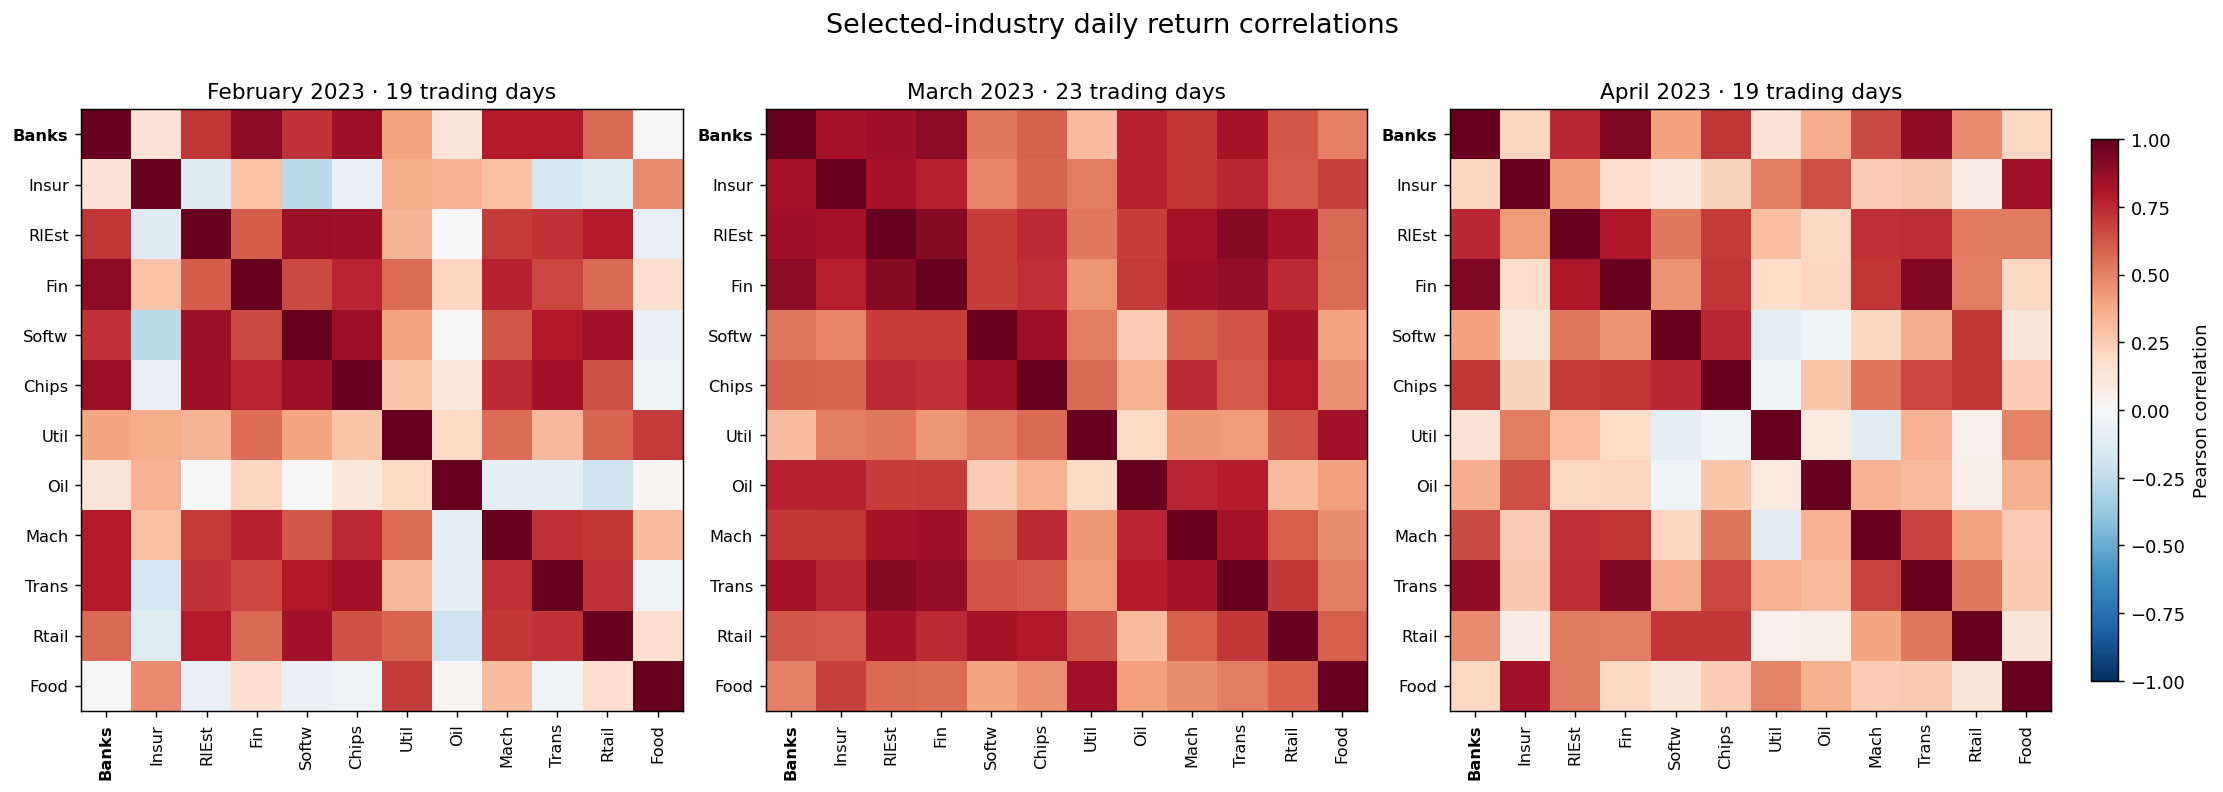

In [99]:
import matplotlib.pyplot as plt

months = ["February", "March", "April"]
industry_order = list(network_results["February"]["correlation"].columns)

fig, axes = plt.subplots(
    1, 3,
    figsize=(17, 6),
    constrained_layout=True
)

for ax, month in zip(axes, months):
    correlation = network_results[month]["correlation"].loc[
        industry_order, industry_order
    ]

    im = ax.imshow(
        correlation.to_numpy(),
        cmap="RdBu_r",
        vmin=-1,
        vmax=1
    )

    ax.set_xticks(range(len(industry_order)))
    ax.set_yticks(range(len(industry_order)))
    ax.set_xticklabels(
        industry_order, rotation=90, fontsize=9
    )
    ax.set_yticklabels(industry_order, fontsize=9)

    n_days = len(network_windows[month])
    ax.set_title(f"{month} 2023 · {n_days} trading days")

    # Highlight banking's row and column labels.
    for label in ax.get_xticklabels() + ax.get_yticklabels():
        if label.get_text() == "Banks":
            label.set_fontweight("bold")

fig.colorbar(
    im,
    ax=axes.tolist(),
    label="Pearson correlation",
    shrink=0.75,
    pad=0.02
)

fig.suptitle("Selected-industry daily return correlations", fontsize=15)
plt.show()

In [100]:
industry_names = list(
    network_results["February"]["correlation"].columns
)

industry_estimation = returns.loc["2022", industry_names]
factor_estimation = factors.loc[industry_estimation.index]

market_excess = factor_estimation["Mkt-RF"]

industry_models = {}

for industry in industry_names:
    industry_excess = (
        industry_estimation[industry] - factor_estimation["RF"]
    )

    market_centered = market_excess - market_excess.mean()
    industry_centered = industry_excess - industry_excess.mean()

    beta = (
        (market_centered * industry_centered).sum()
        / (market_centered ** 2).sum()
    )

    alpha = industry_excess.mean() - beta * market_excess.mean()

    industry_models[industry] = {
        "alpha": alpha,
        "beta": beta
    }

industry_models = pd.DataFrame(industry_models).T
industry_models

,alpha,beta
Banks,0.000159,0.938687
Insur,0.000828,0.608952
RlEst,-0.000407,1.185749
Fin,0.000308,1.036942
Softw,-0.000566,1.318042
Chips,-0.000056,1.349151
Util,0.000566,0.517986
Oil,0.002728,0.633670
Mach,0.000444,1.037270
Trans,-0.000128,0.965709


In [101]:
adjusted_windows = {}
adjusted_correlations = {}

for month, data in network_windows.items():
    monthly_factors = factors.loc[data.index]

    abnormal_returns = pd.DataFrame(
        index=data.index,
        columns=data.columns,
        dtype=float
    )

    for industry in data.columns:
        alpha = industry_models.loc[industry, "alpha"]
        beta = industry_models.loc[industry, "beta"]

        industry_excess = data[industry] - monthly_factors["RF"]

        expected_excess = (
            alpha + beta * monthly_factors["Mkt-RF"]
        )

        abnormal_returns[industry] = (
            industry_excess - expected_excess
        )

    adjusted_windows[month] = abnormal_returns
    adjusted_correlations[month] = abnormal_returns.corr()

In [102]:
market_adjustment_comparison = {}

for month in network_windows:
    raw_bank = (
        network_results[month]["correlation"]["Banks"]
        .drop("Banks")
    )

    adjusted_bank = (
        adjusted_correlations[month]["Banks"]
        .drop("Banks")
    )

    market_adjustment_comparison[month] = {
        "raw_mean_correlation": raw_bank.mean(),
        "adjusted_mean_correlation": adjusted_bank.mean(),
        "raw_Banks_Fin": raw_bank["Fin"],
        "adjusted_Banks_Fin": adjusted_bank["Fin"]
    }

market_adjustment_comparison = pd.DataFrame(
    market_adjustment_comparison
).T

market_adjustment_comparison.round(3)

,raw_mean_correlation,adjusted_mean_correlation,raw_Banks_Fin,adjusted_Banks_Fin
February,0.547,0.026,0.895,0.746
March,0.676,0.052,0.894,0.711
April,0.522,0.081,0.930,0.807


In [103]:
adjusted_banking_correlations = pd.DataFrame({
    month: correlation["Banks"].drop("Banks")
    for month, correlation in adjusted_correlations.items()
})

adjusted_banking_correlations = (
    adjusted_banking_correlations
    .sort_values("March", ascending=False)
)

adjusted_banking_correlations.round(3)

,February,March,April
Fin,0.746,0.711,0.807
Oil,0.202,0.602,0.122
Insur,0.402,0.568,-0.252
RlEst,-0.282,0.465,0.326
Trans,0.068,0.299,0.685
Mach,0.282,0.084,0.380
Food,0.046,-0.041,-0.284
Util,-0.200,-0.300,-0.119
Rtail,-0.580,-0.567,-0.294
Softw,-0.535,-0.604,-0.423


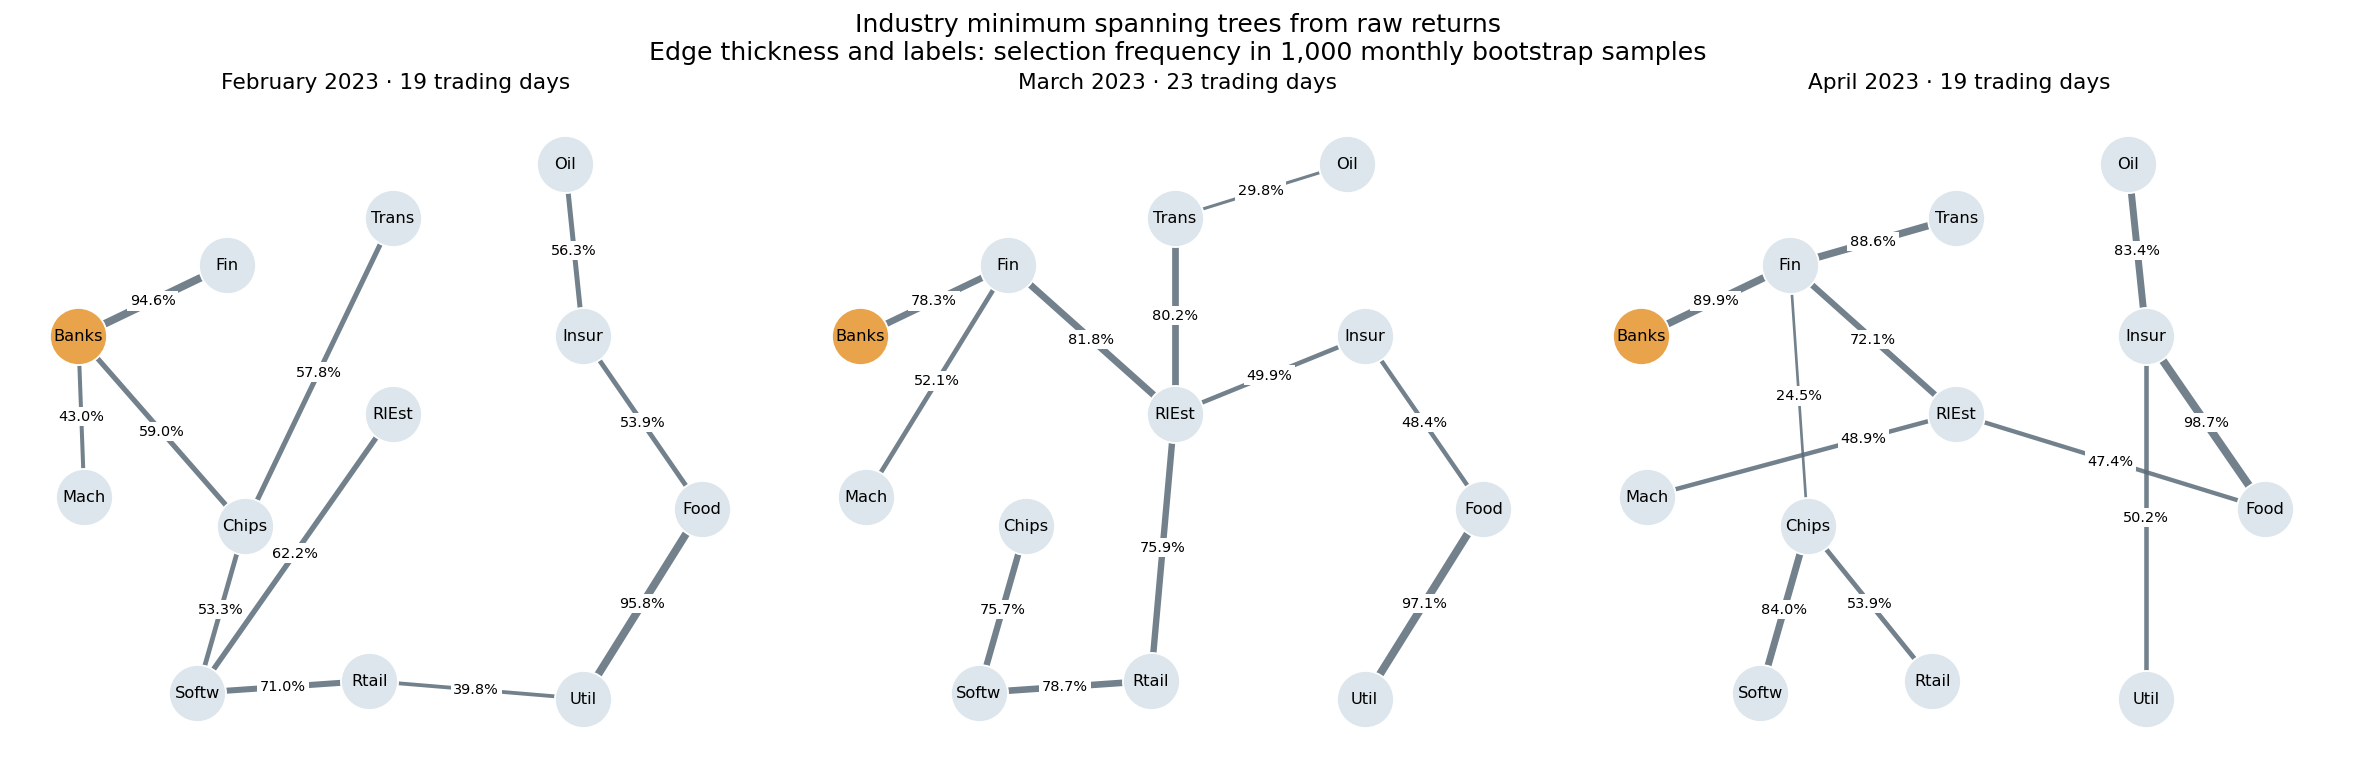

In [104]:
import matplotlib.pyplot as plt

months = ["February", "March", "April"]

# Shared display coordinates: these are not correlation distances.
# Fixed positions also avoid layout changes across NetworkX versions.
positions = {
    "Banks": (0.05, 0.68), "Fin": (0.30, 0.80),
    "Mach": (0.06, 0.41), "Chips": (0.33, 0.36),
    "Softw": (0.25, 0.08), "Rtail": (0.54, 0.10),
    "RlEst": (0.58, 0.55), "Trans": (0.58, 0.88),
    "Oil": (0.87, 0.97), "Insur": (0.90, 0.68),
    "Food": (1.10, 0.39), "Util": (0.90, 0.07)
}

# Move the label away from a crossing in April; edge remains unchanged.
label_fraction = {("April", ("Mach", "RlEst")): 0.70}

fig, axes = plt.subplots(1, 3, figsize=(18, 6), constrained_layout=True)

for ax, month in zip(axes, months):
    result = network_results[month]
    names = result["names"]

    for a, b, distance in result["mst"]:
        industry_a, industry_b = names[a], names[b]
        edge = tuple(sorted((industry_a, industry_b)))
        frequency = mst_bootstrap_results[month].get(edge, 0)
        x1, y1 = positions[industry_a]
        x2, y2 = positions[industry_b]

        ax.plot([x1, x2], [y1, y2], color="#596B78",
                linewidth=0.5 + 4 * frequency, alpha=0.85, zorder=1)

        # Use sorted endpoints so label placement is orientation-independent.
        start_x, start_y = positions[edge[0]]
        end_x, end_y = positions[edge[1]]
        fraction = label_fraction.get((month, edge), 0.5)
        ax.text(start_x + fraction * (end_x - start_x),
                start_y + fraction * (end_y - start_y),
                f"{frequency:.1%}", ha="center", va="center", fontsize=8,
                bbox=dict(facecolor="white", edgecolor="none", pad=1.5),
                zorder=3)

    for industry in names:
        x_pos, y_pos = positions[industry]
        ax.scatter(x_pos, y_pos, s=1000, edgecolors="white",
                   color="#E9A34B" if industry == "Banks" else "#DCE6EC",
                   zorder=4)
        ax.text(x_pos, y_pos, industry, ha="center", va="center",
                fontsize=9, zorder=5)

    ax.set_title(f"{month} 2023 · {len(network_windows[month])} trading days")
    ax.set_xlim(-0.06, 1.23)
    ax.set_ylim(-0.04, 1.08)
    ax.set_aspect("equal")
    ax.set_axis_off()

fig.suptitle(
    "Industry minimum spanning trees from raw returns\n"
    "Edge thickness and labels: selection frequency in 1,000 monthly bootstrap samples",
    fontsize=14
)
plt.show()


In [105]:
network_summary = {}

for month in ["February", "March", "April"]:
    result = network_results[month]
    original_edges = mst_edge_set(result)

    edge_frequencies = [
        mst_bootstrap_results[month].get(edge, 0)
        for edge in original_edges
    ]

    network_summary[month] = {
        "mst_total_distance": sum(
            distance for a, b, distance in result["mst"]
        ),
        "banks_mst_degree": banking_connectivity.loc[
            month, "mst_degree"
        ],
        "banks_raw_mean_correlation": (
            market_adjustment_comparison.loc[
                month, "raw_mean_correlation"
            ]
        ),
        "banks_adjusted_mean_correlation": (
            market_adjustment_comparison.loc[
                month, "adjusted_mean_correlation"
            ]
        ),
        "banks_fin_bootstrap_frequency": (
            mst_bootstrap_results[month].get(
                tuple(sorted(("Banks", "Fin"))),
                0
            )
        ),
        "mean_mst_edge_frequency": np.mean(edge_frequencies),
        "edges_frequency_at_least_70pct": sum(
            frequency >= 0.70
            for frequency in edge_frequencies
        )
    }

network_summary = pd.DataFrame(network_summary).T
network_summary.index.name = "month"

count_columns = ["banks_mst_degree", "edges_frequency_at_least_70pct"]
network_summary[count_columns] = network_summary[count_columns].astype(int)

network_summary.round(3)

,mst_total_distance,banks_mst_degree,banks_raw_mean_correlation,banks_adjusted_mean_correlation,banks_fin_bootstrap_frequency,mean_mst_edge_frequency,edges_frequency_at_least_70pct
month,,,,,,,
February,7.698,3,0.547,0.026,0.946,0.624,3
March,6.159,1,0.676,0.052,0.783,0.680,7
April,7.721,1,0.522,0.081,0.899,0.674,6


## Network interpretation and limits

March's raw-return MST has lower total correlation distance (6.159 versus 7.698 and 7.721). Banking's mean raw correlation peaks in March (0.676), while its MST degree falls from 3 to 1. Global tree selection and average banking correlation measure different features. An MST's average degree is always 2(N−1)/N, so it is uninformative for comparisons with a fixed node count.

Bootstrap mean edge frequencies (0.624, 0.680, 0.674) equal the average fraction of original tree edges retained by a resampled tree. The 70% cutoff yields 3, 7 and 6 original edges; unequal monthly sample sizes and changing conditions prevent interpreting this as a pure economic stability ranking. Edge frequencies do not test whether the monthly tree weights or structures differ significantly.

Adjustment uses industry market models estimated in 2022 and fixed through 2023. Banking's mean adjusted correlations are 0.026, 0.052 and 0.081; March's raw peak disappears. Small adjusted means hide substantial positive and negative associations. March Banks–Fin, Banks–Oil and Banks–Insur remain positive; Banks–Softw and Banks–Chips are negative. These are correlations of deviations from the 2022 benchmark, and need not be uncorrelated with the market in 2023 if exposures changed. A fall in correlation is not an explained-variance decomposition.

Short windows (19, 23, 19 days), ordinary row bootstrap, possible within-month changes, fixed estimated market exposures and the selected industry set limit interpretation. Neither correlation nor MST edges establish causal contagion. Matched-length resampling, network block bootstrap and residual-network MSTs have not been performed. Historical detector alarms remain descriptive because the Gaussian 5% calibration did not transfer to the heavier-tail and empirical-residual baselines.

